# 서울시 시영주차장 30분 뒤 혼잡도 예측 (SVM)

서울 열린데이터 광장 **OA-21709 서울시 시영주차장 실시간 주차대수 정보**로 주차장별 **30분 뒤 혼잡도(여유·보통·혼잡)** 를 예측합니다.

| 단계 | 내용 | 사용 데이터 |
|---|---|---|
| 0 | 준비: 라이브러리, 경로, 설정값 | |
| 1 | 스냅샷 불러오기와 열 이름 정리 | 포털에서 내려받은 CSV (CP949) |
| 2 | 정제: 미연계·버스전용·소형 주차장 제외 | 스냅샷 |
| 3 | 점유율 계산과 분포 | 스냅샷 |
| 4 | 혼잡도 3단계 라벨링 | 스냅샷 |
| 5 | 시계열 불러오기와 수집 간격 점검 | `data/collected/raw` (없으면 가상 데이터) |
| 6 | 예측 대상 만들기: 30분 뒤 혼잡도 | 시계열 |
| 7 | 특성 만들기 | 시계열 |
| 8 | 시간 순서로 학습·테스트 나누기 | 시계열 |
| 9 | 모델 학습: 기준선 → LinearSVC → RBF SVC → SVR+구간 | 시계열 |
| 10 | 평가: macro F1, 클래스별 재현율, 혼동 행렬 | 시계열 |
| 11 | 정리와 다음 할 일 | |

**데이터 준비**
- 포털에서 내려받은 CSV를 `data/snapshot/` 에 둡니다 (파일 이름은 상관없고, 가장 최근 파일을 씁니다).
- 수집 데이터는 `bash scripts/sync_data.sh` 로 `data/collected/` 에 내려받습니다.
- `data/collected/raw/` 가 비어 있으면 5단계부터 **가상 데이터**로 진행합니다. 이때 나오는 성능 수치는 코드가 끝까지 돌아가는지 확인하는 용도일 뿐, 실제 성능이 아닙니다. 수집 데이터가 쌓이면 **Kernel > Restart & Run All** 로 다시 실행하세요.

## 0. 준비

경로는 `requirements.txt` 가 있는 폴더를 저장소 루트로 찾습니다. 노트북을 `notebooks/` 에서 열어도, 루트에서 열어도 됩니다.

설정값은 모두 이 셀에 모았습니다. 혼잡도 기준(`THRESHOLDS`)은 4·6단계에서 분포를 보고 조정합니다.

In [1]:
import time
import warnings
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import lfilter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, SVR, LinearSVC

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ── 경로 ──────────────────────────────────────────────
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
SNAPSHOT_DIR = DATA_DIR / "snapshot"      # 포털에서 내려받은 CSV
COLLECTED_DIR = DATA_DIR / "collected"    # scripts/sync_data.sh 로 받은 수집 데이터
PROCESSED_DIR = DATA_DIR / "processed"    # 전처리 결과 저장 위치

# ── 문제 정의 ─────────────────────────────────────────
THRESHOLDS = (0.50, 0.85)                 # 여유 < 50% ≤ 보통 < 85% ≤ 혼잡
LEVELS = ["여유", "보통", "혼잡"]
HORIZON = pd.Timedelta("30min")           # 몇 분 뒤를 예측할지
MATCH_TOL = pd.Timedelta("6min")          # 30분 뒤 관측을 찾을 때 허용하는 오차 (수집 지연 대비)
STALE_LIMIT = pd.Timedelta("20min")       # 갱신 시각이 이보다 오래되면 연계 끊김으로 본다

# ── 정제 ──────────────────────────────────────────────
EXCLUDE_BUS_ONLY = True                   # 버스전용 주차장(운영구분 4) 제외
MIN_CAPACITY = 5                          # 총 주차면이 이보다 작으면 제외 (점유율이 너무 크게 출렁임)

# ── 학습 ──────────────────────────────────────────────
TEST_RATIO = 0.2                          # 마지막 20% 기간을 테스트로
ANCHOR_EVERY_30MIN = True                 # 학습 행을 30분 간격으로 줄인다 (SVC 속도, 인접 행 중복 완화)
SVC_TUNE_N = 6_000                        # RBF SVC·SVR 하이퍼파라미터 탐색에 쓸 표본 수
SVC_FIT_N = 20_000                        # RBF SVC·SVR 최종 학습 표본 수
RANDOM_STATE = 42

print(f"저장소: {ROOT.name}  |  스냅샷 CSV {len(list(SNAPSHOT_DIR.glob('*.csv')))}개  |  "
      f"수집 raw {len(list((COLLECTED_DIR / 'raw').glob('*.csv')))}개")

저장소: repo  |  스냅샷 CSV 1개  |  수집 raw 0개


In [2]:
# ── 그래프 기본 스타일 ────────────────────────────────
def set_korean_font():
    installed = {f.name for f in fm.fontManager.ttflist}
    for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans KR"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    print("한글 글꼴을 찾지 못했습니다. 그래프의 한글이 깨지면 나눔고딕 등을 설치하세요.")
    return None

INK = "#191919"        # 본문 글자
INK_2 = "#666666"      # 축 눈금, 보조 글자
GRID = "#e7e7e7"
AXIS = "#c2c2c2"
SERIES = ["#257de0", "#f47230"]                  # 범주형 1·2번 색 (파랑, 주황)
LEVEL_COLORS = ["#84b9f3", "#257de0", "#0f4a96"] # 여유·보통·혼잡: 한 색상의 밝기 단계
CM_CMAP = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#cce3fd", "#6aabf1", "#257de0", "#0f4a96"])

print("글꼴:", set_korean_font())
plt.rcParams.update({
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

글꼴: Noto Sans CJK KR


## 1. 스냅샷 불러오기

포털에서 내려받은 CSV는 **CP949** 인코딩에 **한글 열 이름**이고, 수집기(`src/collect.py`)가 쌓는 CSV는 **UTF-8**에 **API 필드명**(`PKLT_CD`, `TPKCT` …)입니다. 두 형식을 같은 내부 열 이름으로 맞춰서, 이후 코드는 어느 쪽 데이터든 그대로 씁니다.

운영 시각 `0000` 같은 값이 숫자로 바뀌지 않도록 모든 열을 문자열로 읽고, 필요한 열만 숫자로 바꿉니다.

In [3]:
# (내부 이름, 포털 CSV 열 이름, API 필드명)
# static/ 파일의 실제 열 이름이 이 표와 다르면 세 번째 칸만 고치면 된다.
COLUMNS = [
    ("lot_id",      "주차장코드",                    "PKLT_CD"),
    ("lot_name",    "주차장명",                      "PKLT_NM"),
    ("addr",        "주소",                          "ADDR"),
    ("lot_type",    "주차장 종류",                   "PKLT_TYPE"),      # NW 노외 / NS 노상
    ("lot_type_nm", "주차장 종류명",                 "PRK_TYPE_NM"),
    ("oper_se",     "운영구분",                      "OPER_SE"),        # 1 시간제, 4 버스전용, 5 시간제+버스전용
    ("oper_nm",     "운영구분명",                    "OPER_SE_NM"),
    ("live_yn",     "주차현황 정보 제공여부",        "PRK_STTS_YN"),    # 1 실시간 연계, 0 미연계
    ("capacity",    "총 주차면",                     "TPKCT"),
    ("parked",      "현재 주차 차량수",              "NOW_PRK_VHCL_CNT"),
    ("updated_at",  "현재 주차 차량수 업데이트시간", "NOW_PRK_VHCL_UPDT_TM"),
    ("pay_yn",      "유무료구분",                    "PAY_YN"),
    ("wd_open",     "평일 운영 시작시각(HHMM)",      "WD_OPER_BGNG_TM"),
    ("wd_close",    "평일 운영 종료시각(HHMM)",      "WD_OPER_END_TM"),
    ("we_open",     "주말 운영 시작시각(HHMM)",      "WE_OPER_BGNG_TM"),
    ("we_close",    "주말 운영 종료시각(HHMM)",      "WE_OPER_END_TM"),
    ("hd_open",     "공휴일 운영 시작시각(HHMM)",    "LHLDY_OPER_BGNG_TM"),
    ("hd_close",    "공휴일 운영 종료시각(HHMM)",    "LHLDY_OPER_END_TM"),
    ("base_fee",    "기본 주차 요금",                "BSC_PRK_CRG"),
    ("base_min",    "기본 주차 시간(분 단위)",       "BSC_PRK_HR"),
    ("day_max_fee", "일 최대 요금",                  "DAY_MAX_CRG"),
]
NUMERIC_COLS = ["oper_se", "live_yn", "capacity", "parked", "base_fee", "base_min", "day_max_fee"]


def read_csv_any(path):
    # 포털 CSV는 CP949, 수집기 CSV는 UTF-8이다. 모든 열을 문자열로 읽는다.
    for enc in ("utf-8-sig", "cp949"):
        try:
            return pd.read_csv(path, dtype=str, encoding=enc, keep_default_na=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"인코딩을 알 수 없습니다: {path}")


def to_kst_naive(s):
    # 수집기의 collected_at 은 '+09:00' 이 붙은 ISO 8601 이다. KST 기준 시각(시간대 정보 없음)으로 맞춘다.
    t = pd.to_datetime(s, errors="coerce", utc=True)
    return t.dt.tz_convert("Asia/Seoul").dt.tz_localize(None)


def normalize(df):
    # 한글 열 이름 또는 API 필드명을 내부 이름으로 바꾸고 형식을 맞춘다.
    rename = {}
    for name, kor, api in COLUMNS:
        if kor in df.columns:
            rename[kor] = name
        elif api in df.columns:
            rename[api] = name
    keep = (["collected_at"] if "collected_at" in df.columns else []) + list(rename)
    out = df[keep].rename(columns=rename)
    for c in out.columns:
        out[c] = out[c].astype(str).str.strip()
    for c in NUMERIC_COLS:
        if c in out:
            out[c] = pd.to_numeric(out[c], errors="coerce")
    if "updated_at" in out:
        out["updated_at"] = pd.to_datetime(out["updated_at"], errors="coerce")
    if "collected_at" in out:
        out["collected_at"] = to_kst_naive(out["collected_at"])
    return out


snapshot_files = sorted(SNAPSHOT_DIR.glob("*.csv"), key=lambda p: p.stat().st_mtime)
assert snapshot_files, f"{SNAPSHOT_DIR} 에 포털에서 내려받은 CSV를 넣어 주세요."
snapshot_path = snapshot_files[-1]

snap_raw = read_csv_any(snapshot_path)
snap = normalize(snap_raw)

print(f"파일: {snapshot_path.name}")
print(f"원본 {snap_raw.shape[0]}행 × {snap_raw.shape[1]}열 → 사용할 열 {snap.shape[1]}개")
print(f"갱신 시각 범위: {snap['updated_at'].min()} ~ {snap['updated_at'].max()}")
snap.head()

파일: 서울시 시영주차장 실시간 주차대수 정보.csv
원본 122행 × 42열 → 사용할 열 21개
갱신 시각 범위: 2026-11-25 23:03:23 ~ 2026-11-25 23:03:37


,lot_id,lot_name,addr,lot_type,lot_type_nm,oper_se,oper_nm,live_yn,capacity,parked,updated_at,pay_yn,wd_open,wd_close,we_open,we_close,hd_open,hd_close,base_fee,base_min,day_max_fee
0,171721,세종로 공영주차장(시),종로구 세종로 80-1,NW,노외 주차장,1,시간제 주차장,1,1260,206,2026-11-25 23:03:23,Y,0000,2400,0000,2400,0000,2400,430,5,NaN
1,171730,종묘주차장 공영주차장(시),종로구 훈정동 2-0,NW,노외 주차장,1,시간제 주차장,1,1312,381,2026-11-25 23:03:23,Y,0000,2400,0000,2400,0000,2400,400,5,NaN
2,171900,훈련원공원 공영주차장(시),중구 을지로5가 40-3,NW,노외 주차장,1,시간제 주차장,1,873,315,2026-11-25 23:03:23,Y,0000,2400,0000,2400,0000,2400,550,5,NaN
3,172051,한강진역 공영주차장(시),용산구 한남동 728-27,NW,노외 주차장,1,시간제 주차장,1,174,33,2026-11-25 23:03:23,Y,0000,2400,0000,2400,0000,2400,400,5,NaN
4,172065,용산주차빌딩 공영주차장(시),용산구 한강로2가 12-9,NW,노외 주차장,1,시간제 주차장,1,559,134,2026-11-25 23:03:23,Y,0000,2400,0000,2400,0000,2400,270,5,NaN


In [4]:
# 주차장 구성 한눈에 보기
print(snap.groupby(["lot_type_nm", "oper_nm"]).size().rename("주차장 수").to_string())
print()
print(snap["live_yn"].map({1: "실시간 연계", 0: "미연계"}).value_counts().to_string())

lot_type_nm  oper_nm       
노상 주차장       버스전용 주차장          10
             시간제 주차장           56
노외 주차장       버스전용 주차장           1
             시간제 + 버스전용 주차장     1
             시간제 주차장           54

live_yn
실시간 연계    109
미연계        13


## 2. 정제

학습에서 빼는 주차장과 이유입니다.

- **미연계(`live_yn` = 0)**: 현재 주차 대수가 0으로 고정돼 있고 갱신 시각도 비어 있습니다.
- **버스전용 주차장**: 총 주차면이 2~21면이라 한 대만 들어와도 점유율이 크게 뛰고, 승용차 혼잡도와 성격이 다릅니다. (`EXCLUDE_BUS_ONLY` 로 끌 수 있습니다.)
- **총 주차면 `MIN_CAPACITY` 면 미만**: 같은 이유로 점유율이 너무 크게 출렁입니다.

갱신 시각이 오래된 행(연계 끊김)은 시계열에서 행 단위로 거릅니다(5단계).

In [5]:
def clean_lots(df):
    # 학습에 쓸 주차장만 남긴다. 규칙별로 몇 곳이 빠졌는지 함께 돌려준다.
    rules = {
        "실시간 연계 없음(미연계)": df["live_yn"] != 1,
        "버스전용 주차장": (df["oper_se"] == 4) & EXCLUDE_BUS_ONLY,
        f"총 주차면 {MIN_CAPACITY}면 미만": df["capacity"].fillna(0) < MIN_CAPACITY,
    }
    keep = pd.Series(True, index=df.index)
    log = []
    for reason, bad in rules.items():
        n = int((keep & bad).sum())
        keep &= ~bad
        log.append({"제외 사유": reason, "제외": n, "남은 주차장": int(keep.sum())})
    return df[keep].copy(), pd.DataFrame(log)


lots, clean_log = clean_lots(snap)
print(f"전체 {len(snap)}곳")
display(clean_log)

print("미연계 주차장:")
display(snap.loc[snap["live_yn"] != 1, ["lot_name", "lot_type_nm", "capacity", "parked"]])

전체 122곳


,제외 사유,제외,남은 주차장
0,실시간 연계 없음(미연계),13,109
1,버스전용 주차장,10,99
2,총 주차면 5면 미만,0,99


미연계 주차장:


,lot_name,lot_type_nm,capacity,parked
28,청계3(남) 공영주차장(시),노상 주차장,20,0
30,남대문 화물 공영주차장(시),노상 주차장,9,0
42,일원터널 공영주차장(시),노외 주차장,11,0
67,청계2(돈화문로) 공영주차장(시),노상 주차장,10,0
81,청계5(남) 공영주차장(시),노상 주차장,5,0
82,청계5가 공영주차장(시),노상 주차장,20,0
85,청계5(방산동) 공영주차장(시),노상 주차장,36,0
86,소파길노상 공영주차장(시),노상 주차장,21,0
88,남산파출소 공영주차장(시),노상 주차장,13,0
115,면목유수지 공영주차장(시),노외 주차장,567,0


In [6]:
# 스냅샷 안에서 갱신 시각이 늦은 주차장이 있는지 (가장 최근 갱신 시각 기준)
ref_time = lots["updated_at"].max()
lots["age"] = ref_time - lots["updated_at"]
print("갱신 지연 분포:")
print(lots["age"].describe()[["min", "50%", "max"]].to_string())
print(f"\n{STALE_LIMIT.seconds // 60}분 넘게 늦은 주차장: {(lots['age'] > STALE_LIMIT).sum()}곳")

갱신 지연 분포:
min    0 days 00:00:00
50%    0 days 00:00:13
max    0 days 00:00:13

20분 넘게 늦은 주차장: 0곳


## 3. 점유율 계산과 분포

**점유율 = 현재 주차 대수 ÷ 총 주차면**

주차 대수가 총 주차면보다 많게 기록되는 경우가 있어 1(100%)에서 자릅니다. 몇 건인지는 먼저 출력합니다.

> 이 스냅샷은 **수요일 밤 11시** 한 시점입니다. 하루 중 가장 한가한 시간대라 분포가 낮은 쪽에 몰려 있는 게 자연스럽고, 혼잡도 기준은 6단계에서 전체 시계열로 다시 봅니다.

In [7]:
lots["occ_raw"] = lots["parked"] / lots["capacity"]
print(f"점유율 100% 초과: {(lots['occ_raw'] > 1).sum()}곳")
lots["occ"] = lots["occ_raw"].clip(0, 1)

display(lots["occ"].describe().round(3).to_frame("점유율").T)
display(lots.groupby("lot_type_nm")["occ"].describe().round(3))

점유율 100% 초과: 0곳


,count,mean,std,min,25%,50%,75%,max
점유율,99.0,0.413,0.234,0.0,0.232,0.387,0.568,1.0


,count,mean,std,min,25%,50%,75%,max
lot_type_nm,,,,,,,,
노상 주차장,46.0,0.403,0.24,0.000,0.198,0.423,0.574,0.889
노외 주차장,53.0,0.422,0.23,0.123,0.232,0.374,0.550,1.000


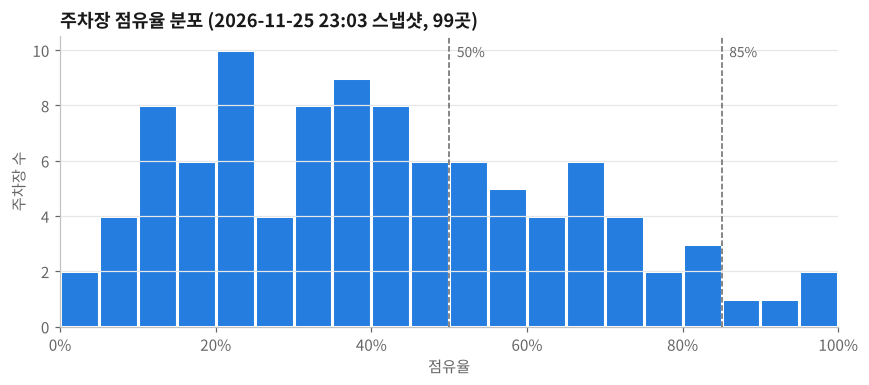

In [8]:
def draw_thresholds(ax, thresholds=THRESHOLDS):
    top = ax.get_ylim()[1]
    for t in thresholds:
        ax.axvline(t, color=INK_2, lw=1, ls="--", zorder=3)
        ax.text(t + 0.01, top * 0.97, f"{t:.0%}", color=INK_2, va="top", fontsize=9)


fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(lots["occ"], bins=np.linspace(0, 1, 21), color=SERIES[0], edgecolor="white", linewidth=2)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("점유율")
ax.set_ylabel("주차장 수")
ax.grid(axis="x", visible=False)
draw_thresholds(ax)
ax.set_title(f"주차장 점유율 분포 ({ref_time:%Y-%m-%d %H:%M} 스냅샷, {len(lots)}곳)", loc="left")
plt.tight_layout()
plt.show()

## 4. 혼잡도 라벨링

| 단계 | 점유율 | 코드 |
|---|---|---|
| 여유 | 50% 미만 | 0 |
| 보통 | 50% 이상 85% 미만 | 1 |
| 혼잡 | 85% 이상 | 2 |

경계값은 위쪽 단계에 넣습니다(50%는 보통, 85%는 혼잡). 아래 후보 기준표는 기준을 바꿨을 때 클래스 비율이 어떻게 달라지는지 보여 줍니다. 클래스가 너무 한쪽에 몰리면 macro F1이 불안정해지므로, 6단계의 전체 시계열 분포를 보고 최종 기준을 정합니다.

In [9]:
def to_level(occ, thresholds=THRESHOLDS):
    # 점유율 → 0(여유) / 1(보통) / 2(혼잡)
    return np.digitize(np.asarray(occ, dtype=float), thresholds)


def level_share(levels):
    counts = np.bincount(np.asarray(levels), minlength=3)
    return pd.DataFrame({"건수": counts, "비율": (counts / counts.sum()).round(3)}, index=LEVELS)


THRESHOLD_CANDIDATES = [(0.40, 0.80), (0.50, 0.85), (0.60, 0.90), (0.70, 0.90)]


def compare_thresholds(occ):
    rows = []
    for th in THRESHOLD_CANDIDATES:
        share = np.bincount(to_level(occ, th), minlength=3) / len(occ)
        rows.append({"기준(보통/혼잡)": f"{th[0]:.0%} / {th[1]:.0%}", **dict(zip(LEVELS, share.round(3)))})
    return pd.DataFrame(rows).set_index("기준(보통/혼잡)")


lots["level"] = to_level(lots["occ"])
print("현재 기준", THRESHOLDS)
display(level_share(lots["level"]))
print("후보 기준별 클래스 비율 (스냅샷)")
display(compare_thresholds(lots["occ"]))

현재 기준 (0.5, 0.85)


,건수,비율
여유,65,0.657
보통,30,0.303
혼잡,4,0.040


후보 기준별 클래스 비율 (스냅샷)


,여유,보통,혼잡
기준(보통/혼잡),,,
40% / 80%,0.515,0.414,0.071
50% / 85%,0.657,0.303,0.040
60% / 90%,0.758,0.212,0.030
70% / 90%,0.869,0.101,0.030


In [10]:
# 지금 가장 붐비는 주차장
top10 = lots.sort_values("occ", ascending=False).head(10)
pd.DataFrame({
    "주차장": top10["lot_name"],
    "종류": top10["lot_type_nm"],
    "총 주차면": top10["capacity"],
    "주차 대수": top10["parked"],
    "점유율": top10["occ"].map("{:.1%}".format),
    "혼잡도": [LEVELS[i] for i in top10["level"]],
})

,주차장,종류,총 주차면,주차 대수,점유율,혼잡도
10,가양3동 공영주차장(시),노외 주차장,56,56,100.0%,혼잡
19,볕우물 공영주차장(시),노외 주차장,96,93,96.9%,혼잡
98,남부여성발전센터 공영주차장(시),노외 주차장,128,117,91.4%,혼잡
90,청계8가 공영주차장(시),노상 주차장,9,8,88.9%,혼잡
54,동대문 공영주차장(시),노외 주차장,1090,923,84.7%,보통
75,동호대교(남) 공영주차장(시),노상 주차장,18,15,83.3%,보통
111,배오개길 공영주차장(시),노상 주차장,10,8,80.0%,보통
121,중곡1동 공영주차장(시),노외 주차장,130,99,76.2%,보통
107,마른내로 공영주차장(시),노상 주차장,12,9,75.0%,보통
11,가양역 공영주차장(시),노외 주차장,79,57,72.2%,보통


## 5. 시계열 불러오기와 수집 간격 점검

**30분 뒤**를 예측하려면 같은 주차장을 10분마다 관측한 시계열이 필요합니다. API가 과거 데이터를 주지 않아서 GitHub Actions가 `data` 브랜치에 직접 쌓고 있습니다.

- `data/collected/raw/*.csv` 가 있으면 → **수집 데이터** 사용 (`bash scripts/sync_data.sh` 로 받기)
- 없으면 → 스냅샷의 주차장 목록으로 **가상 데이터**를 만들어 파이프라인을 점검

가상 데이터 만드는 방식: 스냅샷 주차장의 총 주차면·노상/노외 구분은 그대로 쓰고, 스냅샷 점유율을 밤 시간 기본값으로 둔 뒤 유형별 하루 패턴(역세권 출퇴근형, 노상 업무시간형, 상업형)과 잡음을 얹습니다. 수집 시각은 `collect.yml` 처럼 매시 3·13·23…분에 몇 분씩 늦게 찍히고, 3%는 빠지며, 일부 주차장은 몇 시간 동안 값이 멈춥니다.

GitHub 예약 실행은 늦거나 빠질 수 있으므로 `collected_at` 간격을 반드시 확인합니다.

In [11]:
def load_collected(collected_dir):
    raw_files = sorted((collected_dir / "raw").glob("*.csv"))
    static_files = sorted((collected_dir / "static").glob("*.csv"))
    raw = pd.concat([read_csv_any(f) for f in raw_files], ignore_index=True) if raw_files else None
    static = read_csv_any(static_files[-1]) if static_files else None
    return raw, static


def make_simulated_raw(lot_info, days=14, end=None, seed=RANDOM_STATE):
    # 수집 데이터가 없을 때 파이프라인 점검용 가상 raw 데이터를 collect.py 와 같은 열 형식으로 만든다.
    # 여기서 나온 성능 수치는 실제 성능이 아니다.
    rng = np.random.default_rng(seed)
    end = end or lot_info["updated_at"].max().floor("10min") + pd.Timedelta("3min")
    slots = pd.date_range(end - pd.Timedelta(days=days), end, freq="10min")
    kept = rng.random(len(slots)) > 0.03                                   # 3% 회차 누락
    delay = np.minimum(rng.exponential(2.0, len(slots)), 25)               # 실행 지연(분)
    t = (slots + pd.to_timedelta(delay, unit="min")).round("s")[kept]

    hour = np.asarray(t.hour + t.minute / 60)
    kr_hol = holidays.KR(years=sorted(set(t.year)))
    offday = np.asarray(t.dayofweek >= 5) | np.array([d in kr_hol for d in t.date])
    day_idx = np.asarray((t.normalize() - t.normalize().min()).days)

    def bump(h, center, width):
        return np.exp(-0.5 * ((h - center) / width) ** 2)

    def ramp(h, a, b):
        return np.clip((h - a) / (b - a), 0, 1)

    profiles = {
        "commuter": ramp(hour, 6.5, 9.0) * (1 - ramp(hour, 18.0, 21.5)),   # 역세권 환승: 출근 때 차고 저녁에 빠짐
        "business": bump(hour, 14.0, 3.0),                                 # 노상: 업무시간 중심
        "commercial": 0.7 * bump(hour, 13.0, 2.0) + bump(hour, 19.5, 2.0), # 상업: 점심·저녁
    }
    frames = []
    for _, lot in lot_info.iterrows():
        kind = "business" if lot["lot_type"] == "NS" else ("commuter" if "역" in lot["lot_name"] else "commercial")
        base = float(np.clip(lot["parked"] / lot["capacity"], 0, 0.95))
        amp = rng.uniform(0.4, 1.0) * (1.02 - base)
        off = {"commuter": rng.uniform(0.1, 0.4), "business": rng.uniform(0.2, 0.6),
               "commercial": rng.uniform(0.8, 1.3)}[kind]
        day_factor = rng.normal(1.0, 0.12, day_idx.max() + 1)[day_idx]
        noise = lfilter([1], [1, -0.9], rng.normal(0, 0.025, len(t)))     # AR(1) 잡음
        occ = np.clip(base + amp * profiles[kind] * day_factor * np.where(offday, off, 1.0) + noise, 0, 1)
        parked = np.round(occ * lot["capacity"]).astype(int)
        updated = (t - pd.to_timedelta(rng.uniform(0, 30, len(t)), unit="s")).floor("s").to_numpy().copy()
        if rng.random() < 0.08:                                            # 연계 끊김: 3~6시간 값이 멈춤
            s, n = rng.integers(0, len(t) - 40), rng.integers(18, 36)
            parked[s:s + n] = parked[s]
            updated[s:s + n] = updated[s]
        frames.append(pd.DataFrame({
            "collected_at": t.strftime("%Y-%m-%dT%H:%M:%S+09:00"),
            "PKLT_CD": lot["lot_id"],
            "TPKCT": int(lot["capacity"]),
            "NOW_PRK_VHCL_CNT": parked,
            "NOW_PRK_VHCL_UPDT_TM": pd.DatetimeIndex(updated).strftime("%Y-%m-%d %H:%M:%S"),
            "PRK_STTS_YN": "1",
        }))
    return pd.concat(frames, ignore_index=True).astype(str)


raw_csv, static_csv = load_collected(COLLECTED_DIR)
if raw_csv is not None and len(raw_csv):
    DATA_MODE = "collected"
    lot_info = clean_lots(normalize(static_csv))[0] if static_csv is not None else lots.copy()
else:
    DATA_MODE = "simulated"
    lot_info = lots.copy()
    raw_csv = make_simulated_raw(lot_info)

ts = normalize(raw_csv)
ts = ts[ts["lot_id"].isin(lot_info["lot_id"]) & (ts["live_yn"] == 1)]
ts = ts.sort_values(["collected_at", "lot_id"]).reset_index(drop=True)

if DATA_MODE == "simulated":
    print("[가상 데이터] data/collected/raw 에 수집 데이터가 없어 가상 시계열로 진행합니다.")
    print("              아래 성능 수치는 파이프라인 점검용이며 실제 성능이 아닙니다.\n")
else:
    print("[수집 데이터] data/collected/raw 를 사용합니다.\n")
print(f"행 {len(ts):,}개, 주차장 {ts['lot_id'].nunique()}곳")
print(f"기간 {ts['collected_at'].min()} ~ {ts['collected_at'].max()}")
ts.head()

[가상 데이터] data/collected/raw 에 수집 데이터가 없어 가상 시계열로 진행합니다.
              아래 성능 수치는 파이프라인 점검용이며 실제 성능이 아닙니다.

행 194,634개, 주차장 99곳
기간 2026-11-11 23:03:33 ~ 2026-11-25 23:03:43


,collected_at,lot_id,live_yn,capacity,parked,updated_at
0,2026-11-11 23:03:33,1037932,1,91,33,2026-11-11 23:03:21
1,2026-11-11 23:03:33,1051043,1,399,83,2026-11-11 23:03:12
2,2026-11-11 23:03:33,1163833,1,59,27,2026-11-11 23:03:26
3,2026-11-11 23:03:33,1167546,1,21,11,2026-11-11 23:03:24
4,2026-11-11 23:03:33,1208601,1,9,4,2026-11-11 23:03:30


수집 회차 1,966회 / 10분 간격이면 2,017회 → 수집률 97.5%
간격 중앙값 10.1분, 최대 28.9분

5분 이하 (앞 회차 지연·중복)      67
5~15분 (정상)            1783
15~25분 (1회 누락)         114
25분 초과 (2회 이상 누락)        1


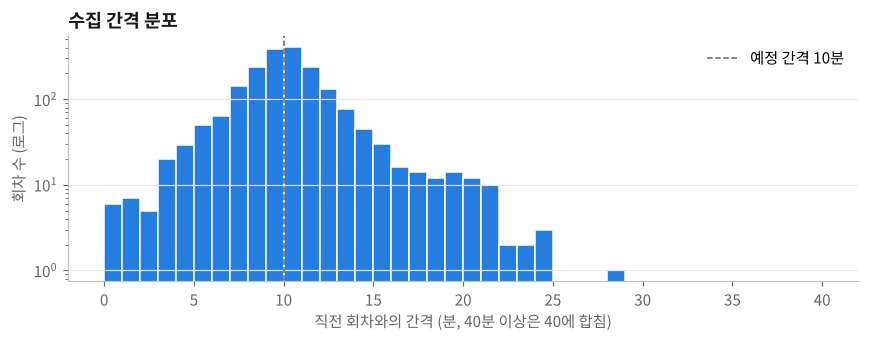

In [12]:
# 수집 간격 점검: 회차(collected_at)별 간격
runs = pd.Series(np.sort(ts["collected_at"].unique()))
gap_min = runs.diff().dt.total_seconds().div(60).dropna()
expected = int((runs.iloc[-1] - runs.iloc[0]) / pd.Timedelta("10min")) + 1

gap_summary = pd.cut(
    gap_min, [0, 5, 15, 25, np.inf],
    labels=["5분 이하 (앞 회차 지연·중복)", "5~15분 (정상)", "15~25분 (1회 누락)", "25분 초과 (2회 이상 누락)"],
).value_counts().sort_index()

print(f"수집 회차 {len(runs):,}회 / 10분 간격이면 {expected:,}회 → 수집률 {len(runs) / expected:.1%}")
print(f"간격 중앙값 {gap_min.median():.1f}분, 최대 {gap_min.max():.1f}분\n")
print(gap_summary.to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(gap_min.clip(upper=40), bins=np.arange(0, 41, 1), color=SERIES[0], edgecolor="white", linewidth=1)
ax.axvline(10, color=INK_2, lw=1, ls="--", label="예정 간격 10분")
ax.legend(loc="upper right")
ax.set_yscale("log")
ax.set_xlabel("직전 회차와의 간격 (분, 40분 이상은 40에 합침)")
ax.set_ylabel("회차 수 (로그)")
ax.grid(axis="x", visible=False)
ax.set_title("수집 간격 분포", loc="left")
plt.tight_layout()
plt.show()

In [13]:
# 연계 끊김: 수집 시각보다 갱신 시각이 STALE_LIMIT 이상 오래된 행은 값이 멈춘 것으로 보고 뺀다
ts["age"] = ts["collected_at"] - ts["updated_at"]
ts["stale"] = ts["updated_at"].isna() | (ts["age"] > STALE_LIMIT)
print(f"연계 끊김 행: {ts['stale'].sum():,}개 ({ts['stale'].mean():.2%})")
if ts["stale"].any():
    top = (ts[ts["stale"]].groupby("lot_id").size().sort_values(ascending=False).head(5)
           .rename("끊긴 행 수").to_frame()
           .join(lot_info.set_index("lot_id")["lot_name"]))
    display(top)
ts = ts[~ts["stale"]].drop(columns=["stale"]).reset_index(drop=True)

ts["occ_raw"] = ts["parked"] / ts["capacity"]
print(f"점유율 100% 초과 행: {(ts['occ_raw'] > 1).sum():,}개 (1로 자름)")
ts["occ"] = ts["occ_raw"].clip(0, 1)

연계 끊김 행: 203개 (0.10%)


,끊긴 행 수,lot_name
lot_id,,
1037932,33,구로디지털단지역 공영주차장(시)
1452024,30,청계5(동호로_북) 공영주차장(시)
3246959,29,중곡1동 공영주차장(시)
173452,27,사당노외 공영주차장(시)
172051,23,한강진역 공영주차장(시)


점유율 100% 초과 행: 0개 (1로 자름)


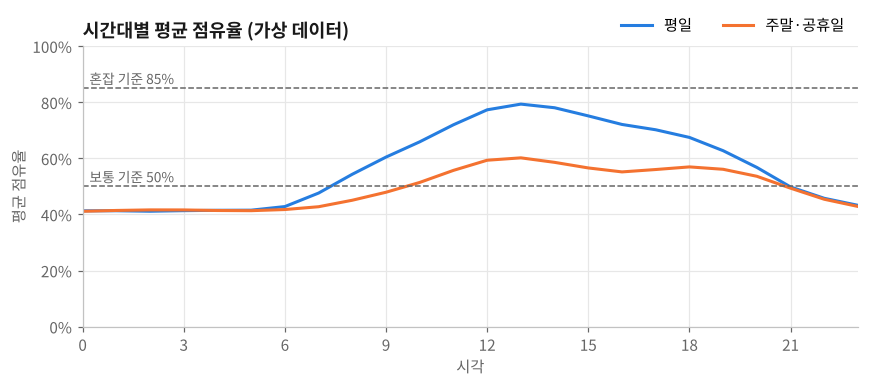

In [14]:
# 달력 정보: 요일, 주말, 공휴일 (공휴일은 holidays 패키지의 한국 공휴일)
KR_HOLIDAYS = holidays.KR(years=range(ts["collected_at"].dt.year.min(), ts["collected_at"].dt.year.max() + 1))

def add_calendar(df):
    t = df["collected_at"]
    df["dow"] = t.dt.dayofweek
    df["hour"] = t.dt.hour
    df["minute_of_day"] = t.dt.hour * 60 + t.dt.minute
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    df["is_holiday"] = t.dt.date.isin(list(KR_HOLIDAYS)).astype(int)
    df["is_offday"] = ((df["is_weekend"] + df["is_holiday"]) > 0).astype(int)
    return df

ts = add_calendar(ts)

profile = ts.groupby(["is_offday", "hour"])["occ"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.6))
for col, label, color in [(0, "평일", SERIES[0]), (1, "주말·공휴일", SERIES[1])]:
    if col in profile:
        ax.plot(profile.index, profile[col], color=color, label=label)
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 3))
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for t, name in zip(THRESHOLDS, ["보통", "혼잡"]):
    ax.axhline(t, color=INK_2, lw=1, ls="--")
    ax.text(0.2, t + 0.015, f"{name} 기준 {t:.0%}", color=INK_2, fontsize=9)
ax.set_xlabel("시각")
ax.set_ylabel("평균 점유율")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_title(f"시간대별 평균 점유율 ({'가상 데이터' if DATA_MODE == 'simulated' else '수집 데이터'})", loc="left")
plt.tight_layout()
plt.show()

## 6. 예측 대상 만들기: 30분 뒤 혼잡도

각 행(주차장 × 수집 시각)에 대해 **같은 주차장의 30분 뒤 관측**을 찾아 붙입니다. 수집 시각이 몇 분씩 흔들리므로 정확히 +30분이 아니라 **+30분에 가장 가까운 관측(±6분 이내)** 을 씁니다(`merge_asof`). 그 사이 회차가 빠졌으면 타깃이 비어서 그 행은 빠집니다.

**30분 동안 혼잡도가 바뀌는 비율**이 중요합니다. 대부분 그대로라면 "지금 그대로" 기준선이 이미 정확도가 높고, 모델의 가치는 **바뀌는 구간**을 맞히는 데서 나옵니다. 그래서 10단계에서 변화 구간 성능을 따로 봅니다.

In [15]:
def value_at(df, offset, tol=MATCH_TOL):
    # 각 행의 (수집 시각 + offset) 에 가장 가까운 같은 주차장 관측(tol 이내)의 점유율과 그 시각
    left = pd.DataFrame({"lot_id": df["lot_id"].astype(object).to_numpy(),
                         "key": (df["collected_at"] + offset).to_numpy(),
                         "row": np.arange(len(df))}).sort_values("key")
    right = pd.DataFrame({"lot_id": df["lot_id"].astype(object).to_numpy(),
                          "key": df["collected_at"].to_numpy(),
                          "occ_match": df["occ"].to_numpy(),
                          "time_match": df["collected_at"].to_numpy()}).sort_values("key")
    m = pd.merge_asof(left, right, on="key", by="lot_id", direction="nearest", tolerance=tol).sort_values("row")
    return m["occ_match"].to_numpy(), pd.to_datetime(m["time_match"].to_numpy())


occ_future, t_future = value_at(ts, HORIZON)
ts["occ_future"] = occ_future
ts["horizon_min"] = (t_future - ts["collected_at"].to_numpy()).total_seconds() / 60

print(f"30분 뒤 관측을 찾은 행: {ts['occ_future'].notna().mean():.1%}")
print("실제 예측 간격(분):", ts["horizon_min"].describe()[["min", "25%", "50%", "75%", "max"]].round(1).to_dict())

30분 뒤 관측을 찾은 행: 95.0%
실제 예측 간격(분): {'min': 24.2, '25%': 28.8, '50%': 30.0, '75%': 31.4, 'max': 36.0}


In [16]:
has_target = ts["occ_future"].notna()
level_now = to_level(ts.loc[has_target, "occ"])
level_future = to_level(ts.loc[has_target, "occ_future"])

print("30분 뒤 혼잡도 분포")
display(level_share(level_future))

print(f"30분 사이 혼잡도가 바뀌는 비율: {(level_now != level_future).mean():.1%}")
print("지금 혼잡도(행) → 30분 뒤 혼잡도(열), 행 기준 비율")
display(pd.crosstab(pd.Categorical([LEVELS[i] for i in level_now], LEVELS),
                    pd.Categorical([LEVELS[i] for i in level_future], LEVELS),
                    normalize="index", rownames=["지금"], colnames=["30분 뒤"]).round(3))

print("후보 기준별 클래스 비율 (전체 시계열)")
display(compare_thresholds(ts["occ"]))

30분 뒤 혼잡도 분포


,건수,비율
여유,77908,0.422
보통,82208,0.445
혼잡,24505,0.133


30분 사이 혼잡도가 바뀌는 비율: 9.3%
지금 혼잡도(행) → 30분 뒤 혼잡도(열), 행 기준 비율


30분 뒤,여유,보통,혼잡
지금,,,
여유,0.936,0.064,0.000
보통,0.061,0.896,0.043
혼잡,0.000,0.147,0.853


후보 기준별 클래스 비율 (전체 시계열)


,여유,보통,혼잡
기준(보통/혼잡),,,
40% / 80%,0.299,0.504,0.197
50% / 85%,0.422,0.445,0.133
60% / 90%,0.555,0.354,0.092
70% / 90%,0.693,0.215,0.092


**기준 조정 메모**: 위 표에서 `혼잡` 비율이 너무 작으면(예: 3% 미만) 혼잡 재현율이 흔들립니다. 그럴 때는 기준을 낮추거나(예: 80%) 클래스 가중치를 유지한 채 테스트 기간을 늘립니다. 기준을 바꾸려면 0단계의 `THRESHOLDS` 를 고치고 처음부터 다시 실행합니다.

## 7. 특성 만들기

| 특성 | 뜻 |
|---|---|
| `occ` | 지금 점유율 |
| `occ_lag10`, `occ_lag20`, `occ_lag30` | 10·20·30분 전 점유율 (타깃과 같은 방식으로 ±6분 이내 관측) |
| `d10`, `d30` | 최근 10분·30분 변화량 (추세) |
| `hour_sin`, `hour_cos` | 하루 중 시각을 원 위에 놓은 값 (23시와 0시가 가깝게) |
| `dow` | 요일 (원-핫) |
| `is_offday` | 주말 또는 공휴일 |
| `is_open` | 운영 시간 안인지 (평일·주말·공휴일 운영 시각 기준) |
| `is_onstreet` | 노상 주차장 여부 |
| `log_capacity` | 총 주차면 (로그) |
| `fee_per_hour` | 시간당 기본 요금 |
| `lot_hour_mean` | 같은 주차장·같은 시각·같은 요일 유형의 **학습 기간** 평균 점유율 (8단계에서 학습 데이터로만 계산) |

운영 시각이 `0000`~`0000` 처럼 시작과 끝이 같으면 24시간 운영으로 간주했습니다. 의미가 다르다고 확인되면 `is_open_at` 을 고치세요.

In [17]:
# 과거 점유율과 변화량
for m in (10, 20, 30):
    ts[f"occ_lag{m}"], _ = value_at(ts, -pd.Timedelta(minutes=m))
ts["d10"] = ts["occ"] - ts["occ_lag10"]
ts["d30"] = ts["occ"] - ts["occ_lag30"]

# 시각
angle = 2 * np.pi * ts["minute_of_day"] / 1440
ts["hour_sin"], ts["hour_cos"] = np.sin(angle), np.cos(angle)

# 주차장 정보
def hhmm_to_min(s):
    v = pd.to_numeric(s, errors="coerce")
    return (v // 100) * 60 + v % 100

static = lot_info[["lot_id", "lot_type", "base_fee", "base_min"]].copy()
for c in ["wd_open", "wd_close", "we_open", "we_close", "hd_open", "hd_close"]:
    static[c] = hhmm_to_min(lot_info[c])
ts = ts.drop(columns=[c for c in static.columns if c != "lot_id" and c in ts]).merge(static, on="lot_id", how="left")

ts["is_onstreet"] = (ts["lot_type"] == "NS").astype(int)
ts["log_capacity"] = np.log1p(ts["capacity"])
ts["fee_per_hour"] = np.where(ts["base_min"] > 0, ts["base_fee"] / ts["base_min"] * 60, 0.0)


def is_open_at(df):
    # 요일 유형별 운영 시각으로 지금이 운영 시간 안인지 계산 (자정을 넘기는 운영도 처리)
    kind = np.where(df["is_holiday"] == 1, "hd", np.where(df["is_weekend"] == 1, "we", "wd"))
    start = np.select([kind == "hd", kind == "we"], [df["hd_open"], df["we_open"]], df["wd_open"])
    end = np.select([kind == "hd", kind == "we"], [df["hd_close"], df["we_close"]], df["wd_close"])
    m = df["minute_of_day"].to_numpy()
    open_ = np.where(start == end, True,                         # 0000~0000, 0000~2400 → 24시간
             np.where(start < end, (m >= start) & (m < end),     # 같은 날 안에서 운영
                      (m >= start) | (m < end)))                 # 자정을 넘겨 운영 (예: 0500~0100)
    return np.where(np.isnan(start) | np.isnan(end), 1, open_).astype(int)


ts["is_open"] = is_open_at(ts)

NUM_FEATURES = ["occ", "occ_lag10", "occ_lag20", "occ_lag30", "d10", "d30", "hour_sin", "hour_cos",
                "is_offday", "is_open", "is_onstreet", "log_capacity", "fee_per_hour", "lot_hour_mean"]
CAT_FEATURES = ["dow"]
FEATURES = NUM_FEATURES + CAT_FEATURES

need = ["occ_future", "occ_lag10", "occ_lag20", "occ_lag30"]
data = ts.dropna(subset=need).copy()
print(f"타깃·과거값이 모두 있는 행: {len(data):,} / {len(ts):,} ({len(data) / len(ts):.1%})")
print("운영 시간 안 비율:", f"{data['is_open'].mean():.1%}")
data[["lot_id", "collected_at"] + [f for f in FEATURES if f != "lot_hour_mean"] + ["occ_future"]].head()

타깃·과거값이 모두 있는 행: 157,215 / 194,431 (80.9%)
운영 시간 안 비율: 63.7%


,lot_id,collected_at,occ,occ_lag10,occ_lag20,occ_lag30,d10,d30,hour_sin,hour_cos,is_offday,is_open,is_onstreet,log_capacity,fee_per_hour,dow,occ_future
297,1037932,2026-11-11 23:35:44,0.362637,0.384615,0.362637,0.362637,-0.021978,0.000000,-0.108867,0.994056,0,1,0,4.521789,3840.0,2,0.428571
298,1051043,2026-11-11 23:35:44,0.295739,0.275689,0.253133,0.208020,0.020050,0.087719,-0.108867,0.994056,0,1,0,5.991465,2880.0,2,0.235589
299,1163833,2026-11-11 23:35:44,0.491525,0.457627,0.440678,0.457627,0.033898,0.033898,-0.108867,0.994056,0,0,1,4.094345,2640.0,2,0.440678
300,1167546,2026-11-11 23:35:44,0.523810,0.523810,0.523810,0.523810,0.000000,0.000000,-0.108867,0.994056,0,0,1,3.091042,4800.0,2,0.523810
301,1208601,2026-11-11 23:35:44,0.444444,0.444444,0.444444,0.444444,0.000000,0.000000,-0.108867,0.994056,0,0,1,2.302585,9000.0,2,0.444444


## 8. 시간 순서로 학습·테스트 나누기

- 무작위로 섞지 않고 **앞 80% 기간 → 학습, 뒤 20% 기간 → 테스트** 로 나눕니다. 섞으면 바로 옆 시각의 거의 같은 행이 학습과 테스트에 동시에 들어가 성능이 부풀려집니다.
- **엠바고**: 학습 행 중 30분 뒤 타깃 시각이 테스트 기간에 걸치는 행은 뺍니다.
- 10분 간격 행은 서로 거의 같아서, 학습·평가 행은 **30분 간격(매시 정각·30분 회차)** 으로 줄입니다. 과거값 특성은 줄이기 전 10분 데이터로 이미 계산했습니다.
- 하이퍼파라미터 탐색은 학습 기간 안에서 `TimeSeriesSplit(3)` 로 합니다.

In [18]:
if ANCHOR_EVERY_30MIN:
    slot = (data["collected_at"] - pd.Timedelta("3min")).dt.floor("10min")   # 매시 3·13·23…분 예약 기준
    data = data[slot.dt.minute.isin([0, 30])]

t0, t1 = data["collected_at"].min(), data["collected_at"].max()
cutoff = t0 + (t1 - t0) * (1 - TEST_RATIO)
train = data[data["collected_at"] + HORIZON + MATCH_TOL < cutoff].sort_values("collected_at")
test = data[data["collected_at"] >= cutoff].sort_values("collected_at")


def add_lot_hour_mean(train, *others):
    # 같은 주차장·시각·요일 유형의 학습 기간 평균 점유율. 학습 데이터로만 계산한다.
    key = ["lot_id", "hour", "is_offday"]
    table = train.groupby(key)["occ"].mean().rename("lot_hour_mean")
    lot_mean = train.groupby("lot_id")["occ"].mean()
    def apply(df):
        df = df.drop(columns="lot_hour_mean", errors="ignore").join(table, on=key)
        return df.assign(lot_hour_mean=df["lot_hour_mean"].fillna(df["lot_id"].map(lot_mean)).fillna(train["occ"].mean()))
    return [apply(train)] + [apply(o) for o in others]


train, test = add_lot_hour_mean(train, test)

X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = to_level(train["occ_future"]), to_level(test["occ_future"])
r_train = train["occ_future"].to_numpy()

print(f"학습: {train['collected_at'].min():%m-%d %H:%M} ~ {train['collected_at'].max():%m-%d %H:%M}  {len(train):,}행")
print(f"테스트: {test['collected_at'].min():%m-%d %H:%M} ~ {test['collected_at'].max():%m-%d %H:%M}  {len(test):,}행")
display(pd.concat({"학습": level_share(y_train), "테스트": level_share(y_test)}, axis=1))

학습: 11-11 23:35 ~ 11-23 02:33  40,838행
테스트: 11-23 04:05 ~ 11-25 22:34  11,369행


학습          테스트       
       건수     비율    건수     비율
여유  18104  0.443  3969  0.349
보통  17729  0.434  5502  0.484
혼잡   5005  0.123  1898  0.167

## 9. 모델 학습

| 모델 | 설명 |
|---|---|
| 기준선: 최빈 클래스 | 늘 가장 흔한 클래스를 답함 |
| 기준선: 지금 그대로 | 30분 뒤 혼잡도 = 지금 혼잡도 |
| LinearSVC | 선형 SVM. 학습 데이터 전체 사용 |
| RBF SVC | 커널 SVM. 느려서 표본으로 탐색·학습 |
| SVR → 구간 | 30분 뒤 **점유율**을 회귀로 예측한 뒤 기준값으로 3단계로 나눔 |

공통 사항
- 숫자 특성은 `StandardScaler`, 요일은 원-핫 (`ColumnTransformer` 를 파이프라인 안에 넣어 교차검증 폴드마다 따로 맞춤)
- 분류기는 `class_weight="balanced"` 로 적은 클래스(혼잡)에 가중치
- 탐색 기준은 **macro F1**. SVR도 회귀 오차가 아니라 "구간으로 나눈 뒤 macro F1"로 고릅니다.

In [19]:
def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ])


def time_sorted_sample(df, n, seed=RANDOM_STATE):
    # 학습 기간 안에서 n개를 뽑아 시간순으로 정렬 (TimeSeriesSplit 이 시간 순서를 지키도록)
    if len(df) > n:
        df = df.sample(n=n, random_state=seed)
    return df.sort_values("collected_at")


def show_search(search, top=5):
    cols = [c for c in search.cv_results_ if c.startswith("param_")]
    res = pd.DataFrame(search.cv_results_)[cols + ["mean_test_score", "std_test_score", "mean_fit_time"]]
    res.columns = [c.replace("param_", "") for c in cols] + ["macro F1 평균", "표준편차", "학습 시간(초)"]
    return res.sort_values("macro F1 평균", ascending=False).head(top).round(4)


cv = TimeSeriesSplit(n_splits=3)
preds, fit_sec = {}, {}

### 9-1. 기준선

In [20]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
preds["기준선: 최빈 클래스"] = dummy.predict(X_test)
preds["기준선: 지금 그대로"] = to_level(test["occ"])
print("최빈 클래스:", LEVELS[dummy.classes_[np.argmax(dummy.class_prior_)]])

최빈 클래스: 여유


### 9-2. LinearSVC

In [21]:
lin_search = GridSearchCV(
    Pipeline([("prep", make_prep()), ("clf", LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE))]),
    {"clf__C": [0.01, 0.1, 1, 10]},
    cv=cv, scoring="f1_macro", n_jobs=-1,
)
start = time.perf_counter()
lin_search.fit(X_train, y_train)
fit_sec["LinearSVC"] = time.perf_counter() - start

preds["LinearSVC"] = lin_search.predict(X_test)
print(f"최적 {lin_search.best_params_}, 탐색+학습 {fit_sec['LinearSVC']:.1f}초 ({len(X_train):,}행)")
show_search(lin_search)

최적 {'clf__C': 10}, 탐색+학습 1.8초 (40,838행)


,clf__C,macro F1 평균,표준편차,학습 시간(초)
3,10.00,0.8813,0.0189,0.0870
2,1.00,0.8810,0.0191,0.0838
1,0.10,0.8801,0.0197,0.0886
0,0.01,0.8764,0.0218,0.0972


### 9-3. RBF SVC

RBF SVC는 학습 시간이 행 수의 제곱 이상으로 늘어서, `SVC_TUNE_N` 개 표본으로 `C`·`gamma` 를 고르고 `SVC_FIT_N` 개 표본으로 최종 학습합니다. 수집 데이터가 수십만 행이 되면 `Nystroem` 근사 + `LinearSVC` 로 바꾸는 것도 방법입니다.

In [22]:
tune = time_sorted_sample(train, SVC_TUNE_N)
rbf_search = GridSearchCV(
    Pipeline([("prep", make_prep()), ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
    {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    cv=cv, scoring="f1_macro", n_jobs=-1,
)
start = time.perf_counter()
rbf_search.fit(tune[FEATURES], to_level(tune["occ_future"]))
tune_sec = time.perf_counter() - start

fit_df = time_sorted_sample(train, SVC_FIT_N)
start = time.perf_counter()
rbf = clone(rbf_search.best_estimator_).fit(fit_df[FEATURES], to_level(fit_df["occ_future"]))
fit_sec["RBF SVC"] = time.perf_counter() - start

preds["RBF SVC"] = rbf.predict(X_test)
print(f"최적 {rbf_search.best_params_}")
print(f"탐색 {tune_sec:.1f}초 ({len(tune):,}행), 최종 학습 {fit_sec['RBF SVC']:.1f}초 ({len(fit_df):,}행), "
      f"서포트 벡터 {rbf.named_steps['clf'].n_support_.sum():,}개")
show_search(rbf_search)

최적 {'clf__C': 10, 'clf__gamma': 'scale'}
탐색 1.7초 (6,000행), 최종 학습 1.9초 (20,000행), 서포트 벡터 4,201개


,clf__C,clf__gamma,macro F1 평균,표준편차,학습 시간(초)
3,10,scale,0.8922,0.0160,0.0558
4,10,0.01,0.8894,0.0118,0.0505
2,1,0.1,0.8891,0.0138,0.0604
0,1,scale,0.8877,0.0121,0.0574
7,100,0.01,0.8863,0.0143,0.0607


### 9-4. SVR → 구간 나누기

30분 뒤 점유율을 직접 예측하면 "얼마나 붐빌지"를 연속값으로 얻고, 기준값이 바뀌어도 다시 학습하지 않고 구간만 새로 나누면 됩니다.

In [23]:
def f1_after_binning(estimator, X, y):
    # SVR 예측 점유율을 혼잡도로 나눈 뒤 macro F1
    return f1_score(to_level(y), to_level(estimator.predict(X)), average="macro")


svr_search = GridSearchCV(
    Pipeline([("prep", make_prep()), ("reg", SVR(kernel="rbf"))]),
    {"reg__C": [1, 10], "reg__epsilon": [0.02, 0.05], "reg__gamma": ["scale", 0.1]},
    cv=cv, scoring=f1_after_binning, n_jobs=-1,
)
start = time.perf_counter()
svr_search.fit(tune[FEATURES], tune["occ_future"].to_numpy())
tune_sec = time.perf_counter() - start

start = time.perf_counter()
svr = clone(svr_search.best_estimator_).fit(fit_df[FEATURES], fit_df["occ_future"].to_numpy())
fit_sec["SVR → 구간"] = time.perf_counter() - start

svr_occ = np.clip(svr.predict(X_test), 0, 1)
preds["SVR → 구간"] = to_level(svr_occ)

mae_svr = np.abs(svr_occ - test["occ_future"]).mean()
mae_now = np.abs(test["occ"] - test["occ_future"]).mean()
print(f"최적 {svr_search.best_params_}")
print(f"탐색 {tune_sec:.1f}초, 최종 학습 {fit_sec['SVR → 구간']:.1f}초 ({len(fit_df):,}행)")
print(f"점유율 평균절대오차: SVR {mae_svr:.2%}p vs 지금 그대로 {mae_now:.2%}p")
show_search(svr_search)

최적 {'reg__C': 1, 'reg__epsilon': 0.05, 'reg__gamma': 'scale'}
탐색 12.5초, 최종 학습 7.2초 (20,000행)
점유율 평균절대오차: SVR 4.01%p vs 지금 그대로 4.13%p


,reg__C,reg__epsilon,reg__gamma,macro F1 평균,표준편차,학습 시간(초)
2,1,0.05,scale,0.8828,0.0108,0.2039
0,1,0.02,scale,0.8825,0.0135,0.4924
3,1,0.05,0.1,0.8800,0.0122,0.1771
6,10,0.05,scale,0.8799,0.0161,0.5591
1,1,0.02,0.1,0.8788,0.0174,0.5405


## 10. 평가

- **macro F1**: 세 클래스의 F1을 단순 평균. 클래스 비율이 치우쳐도 혼잡을 놓치면 점수가 떨어집니다.
- **클래스별 재현율**: 실제 혼잡인 경우 중 몇 %를 혼잡으로 맞혔는지 등.
- **변화 구간**: 테스트 중 30분 사이 혼잡도가 바뀌는 행만 따로 본 성능. "지금 그대로" 기준선은 여기서 정의상 정확도 0%이므로, 모델이 실제로 무엇을 더하는지는 이 표에서 드러납니다.

In [24]:
def scores(y_true, y_pred):
    labels = np.unique(y_true)   # 이 구간에 실제로 있는 클래스만 macro 평균에 넣는다
    rec = recall_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    present = np.isin([0, 1, 2], labels)
    return {
        "macro F1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0),
        "정확도": accuracy_score(y_true, y_pred),
        **{f"재현율 {lv}": (r if p else np.nan) for lv, r, p in zip(LEVELS, rec, present)},
    }


changed = to_level(test["occ"]) != y_test
result_all = pd.DataFrame({n: scores(y_test, p) for n, p in preds.items()}).T
result_chg = pd.DataFrame({n: scores(y_test[changed], p[changed]) for n, p in preds.items()}).T

print(f"테스트 {len(y_test):,}행 전체")
display(result_all.round(3))
print(f"변화 구간: 30분 사이 혼잡도가 바뀌는 {changed.sum():,}행 ({changed.mean():.1%})")
display(result_chg.round(3))

테스트 11,369행 전체


,macro F1,정확도,재현율 여유,재현율 보통,재현율 혼잡
기준선: 최빈 클래스,0.173,0.349,1.000,0.000,0.000
기준선: 지금 그대로,0.888,0.895,0.925,0.887,0.856
LinearSVC,0.885,0.892,0.947,0.865,0.859
RBF SVC,0.879,0.887,0.924,0.846,0.925
SVR → 구간,0.892,0.900,0.941,0.886,0.856


변화 구간: 30분 사이 혼잡도가 바뀌는 1,196행 (10.5%)


,macro F1,정확도,재현율 여유,재현율 보통,재현율 혼잡
기준선: 최빈 클래스,0.133,0.249,1.000,0.000,0.000
기준선: 지금 그대로,0.000,0.000,0.000,0.000,0.000
LinearSVC,0.293,0.289,0.497,0.223,0.215
RBF SVC,0.423,0.415,0.416,0.340,0.584
SVR → 구간,0.373,0.381,0.477,0.380,0.281


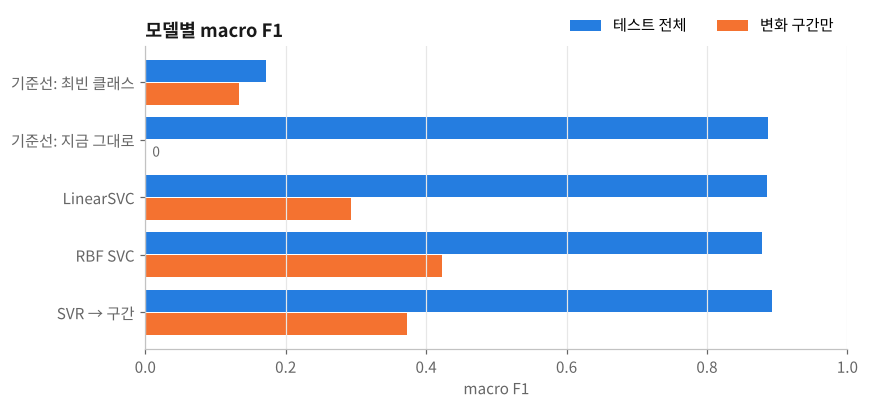

In [25]:
names = list(preds)
y = np.arange(len(names))
h = 0.38
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(y - h / 2 - 0.01, result_all["macro F1"], height=h, color=SERIES[0], label="테스트 전체")
ax.barh(y + h / 2 + 0.01, result_chg["macro F1"], height=h, color=SERIES[1], label="변화 구간만")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("macro F1")
ax.grid(axis="y", visible=False)
for i, v in enumerate(result_chg["macro F1"]):
    if v < 0.02:   # '지금 그대로'는 변화 구간에서 정의상 0이라 막대가 보이지 않는다
        ax.text(0.01, i + h / 2 + 0.01, "0", va="center", color=INK_2, fontsize=9)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_title("모델별 macro F1", loc="left")
plt.tight_layout()
plt.show()

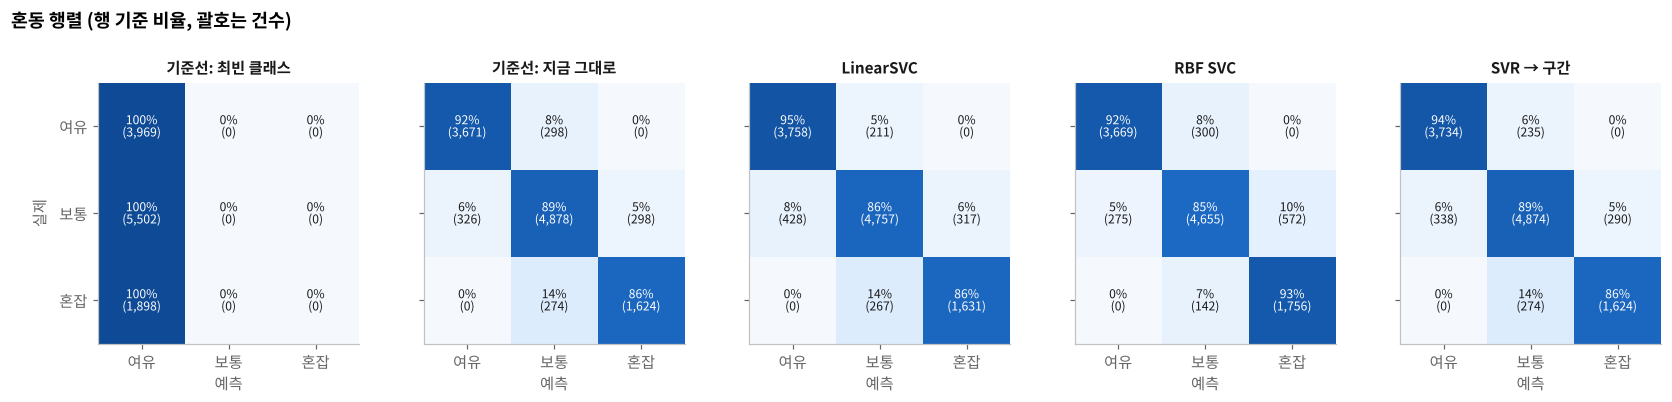

In [26]:
fig, axes = plt.subplots(1, len(preds), figsize=(3.1 * len(preds), 3.4), sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=[0, 1, 2])
    rate = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(rate, cmap=CM_CMAP, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{rate[i, j]:.0%}\n({cm[i, j]:,})", ha="center", va="center", fontsize=8,
                    color="white" if rate[i, j] > 0.55 else INK)
    ax.set_xticks(range(3), LEVELS)
    ax.set_yticks(range(3), LEVELS)
    ax.grid(False)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("예측")
axes[0].set_ylabel("실제", labelpad=8)
fig.suptitle("혼동 행렬 (행 기준 비율, 괄호는 건수)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

In [27]:
model_names = [n for n in preds if not n.startswith("기준선")]
best = result_all.loc[model_names, "macro F1"].idxmax()
print(f"macro F1 최고 모델: {best}\n")
print(classification_report(y_test, preds[best], labels=[0, 1, 2], target_names=LEVELS, digits=3, zero_division=0))

macro F1 최고 모델: SVR → 구간

              precision    recall  f1-score   support

          여유      0.917     0.941     0.929      3969
          보통      0.905     0.886     0.896      5502
          혼잡      0.848     0.856     0.852      1898

    accuracy                          0.900     11369
   macro avg      0.890     0.894     0.892     11369
weighted avg      0.900     0.900     0.900     11369



## 11. 정리와 다음 할 일

In [28]:
summary = pd.Series({
    "데이터": "가상 데이터 (파이프라인 점검용)" if DATA_MODE == "simulated" else "수집 데이터",
    "기간": f"{ts['collected_at'].min():%Y-%m-%d %H:%M} ~ {ts['collected_at'].max():%Y-%m-%d %H:%M}",
    "주차장 수": ts["lot_id"].nunique(),
    "혼잡도 기준": f"보통 {THRESHOLDS[0]:.0%} 이상, 혼잡 {THRESHOLDS[1]:.0%} 이상",
    "학습 / 테스트 행": f"{len(train):,} / {len(test):,}",
    "30분 내 혼잡도 변화 비율(테스트)": f"{changed.mean():.1%}",
    "기준선(지금 그대로) macro F1": round(result_all.loc["기준선: 지금 그대로", "macro F1"], 3),
    "최고 모델": best,
    "최고 모델 macro F1 (전체 / 변화 구간)": f"{result_all.loc[best, 'macro F1']:.3f} / {result_chg.loc[best, 'macro F1']:.3f}",
})
summary.to_frame("값")

,값
데이터,가상 데이터 (파이프라인 점검용)
기간,2026-11-11 23:03 ~ 2026-11-25 23:03
주차장 수,99
혼잡도 기준,"보통 50% 이상, 혼잡 85% 이상"
학습 / 테스트 행,"40,838 / 11,369"
30분 내 혼잡도 변화 비율(테스트),10.5%
기준선(지금 그대로) macro F1,0.888
최고 모델,SVR → 구간
최고 모델 macro F1 (전체 / 변화 구간),0.892 / 0.373


In [29]:
# 전처리 결과 저장 (수집 데이터일 때만. 가상 데이터는 저장하지 않는다)
if DATA_MODE == "collected":
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    out = PROCESSED_DIR / f"features_{ts['collected_at'].max():%Y%m%d_%H%M}.parquet"
    data.to_parquet(out, index=False)
    print("저장:", out.relative_to(ROOT))
else:
    print("가상 데이터라 저장하지 않았습니다.")

가상 데이터라 저장하지 않았습니다.


**다음 할 일**

1. **수집 시작 후 다시 실행**: 저장소 관리자가 `SEOUL_API_KEY` 를 등록하면 수집이 시작됩니다. 최소 2주(평일·주말 패턴이 두 번 이상) 쌓인 뒤 `bash scripts/sync_data.sh` → **Restart & Run All**. 그때부터 나오는 수치가 실제 결과입니다.
2. **혼잡도 기준 확정**: 6단계의 후보 기준표와 시간대별 점유율 그래프를 보고 `THRESHOLDS` 를 정합니다.
3. **수집 품질 확인**: 5단계 수집률이 낮거나 연계 끊김 주차장이 많으면, 해당 주차장을 빼거나 `MATCH_TOL` 을 조정합니다.
4. **모델 개선**: 데이터가 커지면 RBF SVC 대신 `Nystroem` + `LinearSVC`, 주차장별 성능 비교, 날씨·행사 같은 외부 특성 추가를 검토합니다.
5. **평가 보강**: 테스트 기간을 여러 번 옮겨 가며(롤링) 성능이 안정적인지 확인합니다.